## Assignment 1: Multiple Regression

1. Fit a model on 'speed', 'hd', 'ram', and 'screen' and plot the residuals. 
   
   - Do any features have unintuitive coefficients? 
   
   - Does our model predict better for certain price ranges?  
         
     <br>         
2. Fit a model including all numeric columns (*add 'trend' and 'ads' to the previous model*), and plot the residuals. 
   
   - Do any features have unintuitive coefficients? 
   
   - Does our model predict better for certain price ranges?
   
   Which residual plot looks better?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# ----------------------------------------
import statsmodels.api as sm

In [2]:
computers = pd.read_csv("../datasets/Computers.csv")

computers.tail()

,price,speed,hd,ram,screen,cd,multi,premium,ads,trend
6254,1690,100,528,8,15,no,no,yes,39,35
6255,2223,66,850,16,15,yes,yes,yes,39,35
6256,2654,100,1200,24,15,yes,no,yes,39,35
6257,2195,100,850,16,15,yes,no,yes,39,35
6258,2490,100,850,16,17,yes,no,yes,39,35


### 
EDA

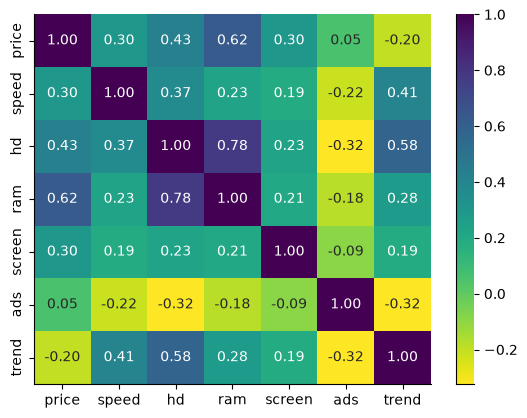

In [3]:
sns.heatmap(data=computers.corr(numeric_only=True),
            annot=True, cmap='viridis_r', fmt='.2f')
sns.despine()

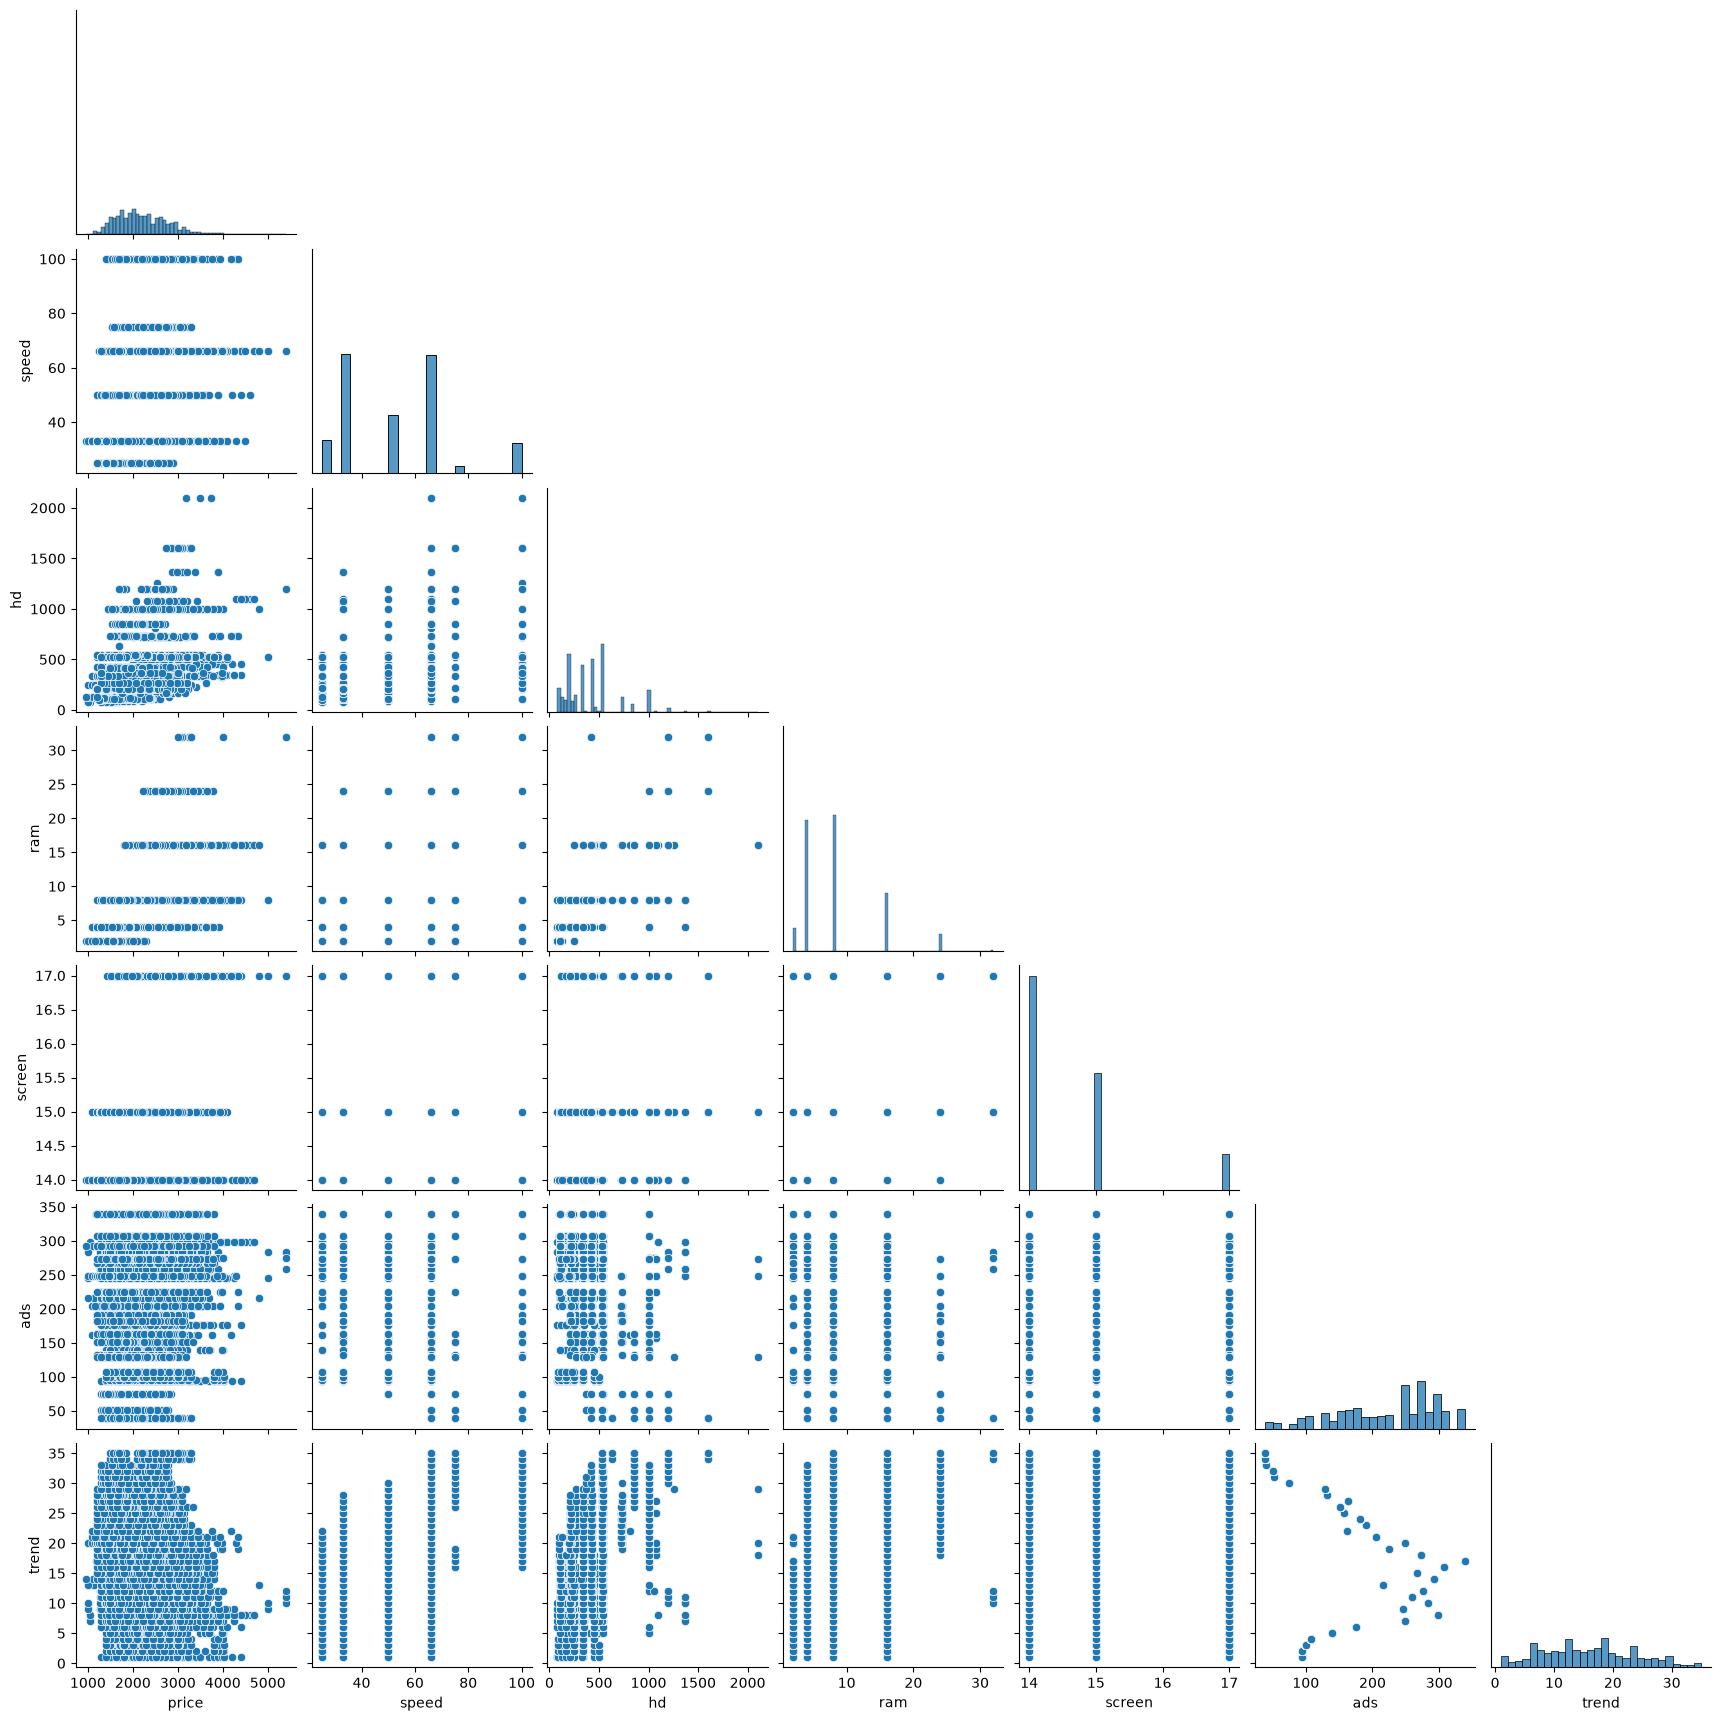

In [4]:
sns.pairplot(computers, corner=True)
sns.despine()

<br><br>

---

### First Model

In [5]:
cols1 = ["ram", "speed", "hd", "screen"]

X = sm.add_constant(computers[cols1])
y = computers['price']

model1 = sm.OLS(y, X).fit()

model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.458
Method:                 Least Squares   F-statistic:                     1325.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:52:50   Log-Likelihood:                -46795.
No. Observations:                6259   AIC:                         9.360e+04
Df Residuals:                    6254   BIC:                         9.363e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.3331     88.222      0.117      0.907    -162.613     183.279
ram           76.7454      1.536     49.969      0.000      73.735      79.756
speed          5.2493      0.278     18.858      0.000       4.704       5.795
hd            -0.5794      0.035    -16.520      0.000      -0.648      -0.511
screen       105.5259      6.189     17.051      0.000      93.394     117.658
==============================================================================
Omnibus:                     1640.957   Durbin-Watson:                   1.484
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             5072.066
Skew:                           1.340   Prob(JB):                         0.00
Kurtosis:                       6.503   Cond. No.                     8.07e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.07e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

<br>

>---
>Now it's time to plot the `residuals` and `predictions` of the first model
>

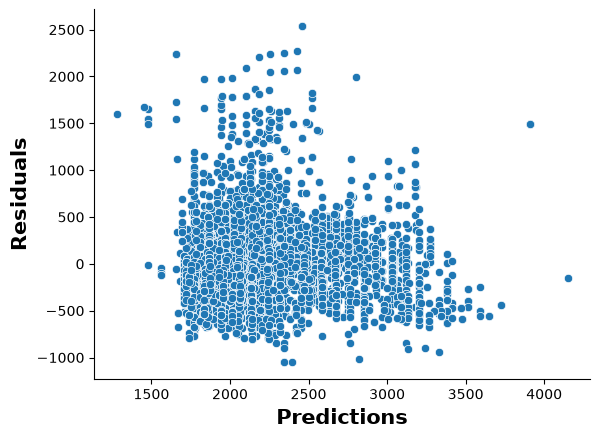

In [6]:
sns.scatterplot(x=model1.predict(), y=model1.resid)

plt.xlabel('Predictions', fontweight='bold', fontsize=15)
plt.ylabel('Residuals', fontweight='bold', fontsize=15)

sns.despine()

>---
>
>`PLOT INTERPRETATION:` The upper plot shows that **Cheaper computers have a lower accuracy on our predictions** (*almost 2000 USD on error*), compared with the most expensive ones that present **Higher accuracy** (*almost error error*).
>
>---

<br><br>

---

### Second Model

In [7]:
cols2 = ["ram", "speed", "hd", "screen", "ads", "trend"]

X2 = sm.add_constant(computers[cols2])
y = computers.price

model2 = sm.OLS(y, X2).fit()

model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.712
Method:                 Least Squares   F-statistic:                     2580.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:52:50   Log-Likelihood:                -44817.
No. Observations:                6259   AIC:                         8.965e+04
Df Residuals:                    6252   BIC:                         8.969e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -246.6755     66.371     -3.717      0.000    -376.785    -116.566
ram           47.3870      1.188     39.899      0.000      45.059      49.715
speed          8.8939      0.209     42.590      0.000       8.485       9.303
hd             0.7088      0.031     22.932      0.000       0.648       0.769
screen       126.7024      4.521     28.022      0.000     117.839     135.566
ads            0.9697      0.057     17.099      0.000       0.859       1.081
trend        -47.0820      0.676    -69.660      0.000     -48.407     -45.757
==============================================================================
Omnibus:                     1407.073   Durbin-Watson:                   1.948
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3902.981
Skew:                           1.187   Prob(JB):                         0.00
Kurtosis:                       6.054   Cond. No.                     8.89e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.89e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

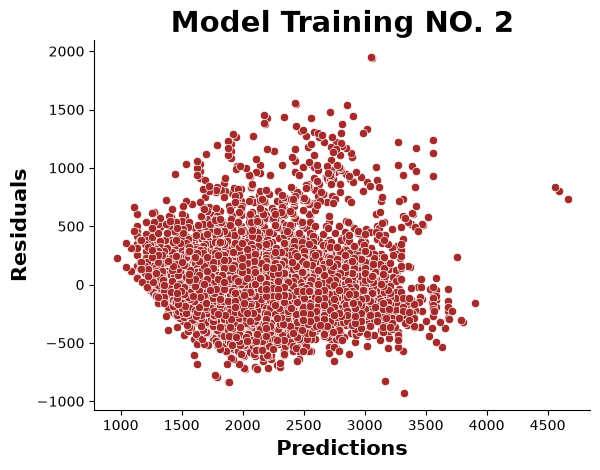

In [8]:
# Now lets see the residuals of Model 2
sns.scatterplot(x=model2.predict(), y=model2.resid, c='brown')

plt.title('Model Training NO. 2', fontweight='bold', fontsize=21)
plt.xlabel('Predictions', fontweight='bold', fontsize=15)
plt.ylabel('Residuals', fontweight='bold', fontsize=15)

sns.despine()

>---
>
>`PLOT INTERPRETATION:`
>
>- The upper plot shows now that **Cheaper and the most expensive computers have the Highest accuracy on our predictions** (*near 500 USD of error*).
>
>- On the other hand now the middle price of computers present the **Lower range of accuracy**, where the highst value of error reaches around 2000 USD.
>
>---

<br><br>

<br><br>

---

## Assignment 2: Metrics

In [9]:
from sklearn.metrics import mean_absolute_error as mae, root_mean_squared_error as rmse

In [10]:
def regression_error(data, features, target):
    X = sm.add_constant(data[features])
    y = data[target]

    model = sm.OLS(y, X).fit()

    df = pd.DataFrame({'MAE': mae(y, model.predict()),
                       'RMSE': rmse(y, model.predict())
                      }, index=['USD']).round(3)
    return df

<br>

---

1. Calculate MAE and RMSE for the `price` model with just RAM.

In [11]:
X1 = 'ram'
y = 'price'

regression_error(computers, X1, y)

,MAE,RMSE
USD,344.145,454.398


<br>

---

2. Calculate MAE and RMSE for the `price` model with all numeric variables.

In [12]:
X2 = computers.select_dtypes(include='number').drop(labels='price', axis=1).columns

regression_error(computers, X2, y)

,MAE,RMSE
USD,225.563,311.502


In [13]:
print(model1.summary(title='OLS Regression Results with RAM and Price'))
print('\n\n')
print(model2.summary(title='OLS Regression Results with all Numeric Values'))

                  OLS Regression Results with RAM and Price                   
Dep. Variable:                  price   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.458
Method:                 Least Squares   F-statistic:                     1325.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:52:50   Log-Likelihood:                -46795.
No. Observations:                6259   AIC:                         9.360e+04
Df Residuals:                    6254   BIC:                         9.363e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.3331     88.222      0.117      0.9